# m16 - Spark MLlib vs scikit-learn: the Same Models With and Without a Big Data Framework

**Question.** Does the distributed machine-learning library of Apache Spark (MLlib) reproduce the scikit-learn results on
this table, and what does it cost or buy in time? The workload is small (9,129 cells x 14 drivers), so this is also a look
at where a cluster framework starts to pay off.

**Setup.** Identical data, inputs and folds on both sides: the 9,129 cells with a 1 km target, the 14 physical drivers and
the 5 pixel-grouped folds of m01 (passed to Spark as a fold column). MLlib regressors are single-output, so every crop gets
its own model on both sides.

| model family | Spark MLlib (`pyspark.ml`) | scikit-learn |
| --- | --- | --- |
| linear | `LinearRegression` (ridge penalty) on standardised inputs | `RidgeCV` on standardised inputs |
| random forest | `RandomForestRegressor`, 60 trees, depth 12, 1/3 of the inputs per split | `RandomForestRegressor`, same settings |
| gradient boosting | `GBTRegressor`, 30 rounds, depth 5, step 0.15 | `HistGradientBoostingRegressor`, same settings |
| reference | - | ExtraTrees, the best tree model of m01 |

Both pipelines impute missing inputs with the training median (scikit-learn's histogram boosting handles them
natively). Spark runs in local mode with 6 cores (`exp_spark.py`). MLlib bins every input into 32 values, scikit-learn's
forest uses exact splits; that is the main algorithmic difference. The whole notebook takes about eight minutes.

In [1]:
import sys
import time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

# Make exp_lib importable no matter where the notebook is launched from.
HERE = next(p for p in (Path.cwd(), Path.cwd() / "scripts" / "modeling") if (p / "exp_lib.py").exists())
sys.path.insert(0, str(HERE))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

import exp_lib as E
import exp_spark as S
from threadpoolctl import threadpool_limits

threadpool_limits(E.N_JOBS)   # BLAS/OpenMP in this kernel stay within the same CPU budget as Spark
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160)

In [2]:
df = E.load_table()
FEATURES = E.feature_columns()
SPLITS = E.make_splits(df, "pixel", 5, seed=0)
fold = np.empty(len(df), dtype=int)
for k, (_, te) in enumerate(SPLITS):
    fold[te] = k
Y = df[E.gaez_cols()].to_numpy(float)
X = df[FEATURES].to_numpy(float)
pdf = df[FEATURES].assign(fold=fold, row_id=np.arange(len(df)))
for j, c in enumerate(E.CROPS):
    pdf[f"y_{c}"] = Y[:, j]
RF = dict(trees=60, depth=12)
GB = dict(rounds=30, depth=5, rate=0.15)
print(f"{len(df)} cells, {len(FEATURES)} drivers, {len(E.CROPS)} crops, {len(SPLITS)} pixel-grouped folds")

9129 cells, 14 drivers, 10 crops, 5 pixel-grouped folds


## 1. Without Spark: scikit-learn

In [3]:
SKLEARN = {
    "Linear (ridge)": lambda: make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 13))),
    "Random forest": lambda: make_pipeline(SimpleImputer(strategy="median"), RandomForestRegressor(
        RF["trees"], max_depth=RF["depth"], max_features=1 / 3, n_jobs=E.N_JOBS, random_state=0)),
    "Gradient boosting": lambda: HistGradientBoostingRegressor(max_iter=GB["rounds"], max_depth=GB["depth"],
                                                               learning_rate=GB["rate"], random_state=0),
    "ExtraTrees (reference)": lambda: make_pipeline(SimpleImputer(strategy="median"), ExtraTreesRegressor(
        100, min_samples_leaf=3, max_features=0.7, n_jobs=E.N_JOBS, random_state=0)),
}
oof, wall = {}, {}
for name, make in SKLEARN.items():
    pred = np.zeros_like(Y)
    t0 = time.perf_counter()
    for j in range(len(E.CROPS)):
        for tr, te in SPLITS:
            pred[te, j] = make().fit(X[tr], Y[tr, j]).predict(X[te])
    wall[("scikit-learn", name)] = time.perf_counter() - t0
    oof[("scikit-learn", name)] = np.clip(pred, 0, 10000)
    print(f"scikit-learn  {name:24s} {wall[('scikit-learn', name)]:6.1f} s", flush=True)

scikit-learn  Linear (ridge)              1.2 s


scikit-learn  Random forest              11.2 s


scikit-learn  Gradient boosting           2.9 s


scikit-learn  ExtraTrees (reference)     11.9 s


## 2. With Spark: MLlib pipelines

Each fit is a `pyspark.ml.Pipeline` (`Imputer` -> `VectorAssembler` -> [`StandardScaler`] -> regressor) trained on the
training folds of a Spark DataFrame and applied to the held-out fold. Three crops are fitted at a time from separate driver
threads, so the small Spark jobs keep the six cores busy.

In [4]:
spark = S.session("m16-mllib")
from pyspark.ml import Pipeline  # noqa: E402
from pyspark.ml.feature import Imputer, StandardScaler as SparkScaler, VectorAssembler  # noqa: E402
from pyspark.ml.regression import GBTRegressor, LinearRegression, RandomForestRegressor as SparkForest  # noqa: E402

sdf = spark.createDataFrame(pdf).cache()
print("Spark", spark.version, "| rows in the Spark DataFrame:", sdf.count())
IMPUTED = [f"{c}__imp" for c in FEATURES]


def mllib_pipeline(name, label):
    stages = [Imputer(inputCols=FEATURES, outputCols=IMPUTED, strategy="median"),
              VectorAssembler(inputCols=IMPUTED, outputCol="raw")]
    if name == "Linear (ridge)":
        stages += [SparkScaler(inputCol="raw", outputCol="features", withMean=True, withStd=True),
                   LinearRegression(featuresCol="features", labelCol=label, regParam=0.01, elasticNetParam=0.0)]
    elif name == "Random forest":
        stages += [SparkForest(featuresCol="raw", labelCol=label, numTrees=RF["trees"], maxDepth=RF["depth"],
                               featureSubsetStrategy="onethird", seed=0)]
    else:
        stages += [GBTRegressor(featuresCol="raw", labelCol=label, maxIter=GB["rounds"], maxDepth=GB["depth"],
                                stepSize=GB["rate"], seed=0)]
    return Pipeline(stages=stages)


def mllib_crop(name, j):
    label, parts = f"y_{E.CROPS[j]}", []
    for k in range(len(SPLITS)):
        model = mllib_pipeline(name, label).fit(sdf.filter(sdf.fold != k))
        parts.append(model.transform(sdf.filter(sdf.fold == k)).select("row_id", "prediction").toPandas())
    pred = pd.concat(parts).set_index("row_id")["prediction"].reindex(np.arange(len(df))).to_numpy()
    return j, np.clip(pred, 0, 10000)


for name in ["Linear (ridge)", "Random forest", "Gradient boosting"]:
    pred = np.zeros_like(Y)
    t0 = time.perf_counter()
    with ThreadPoolExecutor(3) as pool:
        for j, p in pool.map(lambda j: mllib_crop(name, j), range(len(E.CROPS))):
            pred[:, j] = p
    wall[("Spark MLlib", name)] = time.perf_counter() - t0
    oof[("Spark MLlib", name)] = pred
    print(f"Spark MLlib   {name:24s} {wall[('Spark MLlib', name)]:6.1f} s", flush=True)

Spark 3.5.9 | rows in the Spark DataFrame: 9129


Spark MLlib   Linear (ridge)             28.3 s


Spark MLlib   Random forest             240.6 s


Spark MLlib   Gradient boosting         155.5 s


## 3. Scores on the same held-out folds

In [5]:
rows = []
for (framework, name), pred in oof.items():
    for j, c in enumerate(E.CROPS):
        rows.append({"framework": framework, "model": name, "crop": c, **E.regression_metrics(Y[:, j], pred[:, j])})
raw = pd.DataFrame(rows)
E.save_table(raw.round(4), "m16_cv_raw")
summary = raw.groupby(["framework", "model"], sort=False)[["r2", "rmse", "spearman"]].mean()
summary["wall seconds (10 crops x 5 folds)"] = [wall[k] for k in summary.index]
summary = summary.reset_index()
E.save_table(summary.round(4), "m16_summary")
summary.round(3)

,framework,model,r2,rmse,spearman,wall seconds (10 crops x 5 folds)
0,scikit-learn,Linear (ridge),0.604,1313.009,0.775,1.223
1,scikit-learn,Random forest,0.808,902.599,0.894,11.207
2,scikit-learn,Gradient boosting,0.797,929.212,0.891,2.892
3,scikit-learn,ExtraTrees (reference),0.819,876.428,0.901,11.919
4,Spark MLlib,Linear (ridge),0.604,1312.856,0.775,28.274
5,Spark MLlib,Random forest,0.806,907.125,0.894,240.571
6,Spark MLlib,Gradient boosting,0.760,1010.920,0.873,155.462


In [6]:
pairs = raw[raw["model"].isin(["Linear (ridge)", "Random forest", "Gradient boosting"])]
gap = pairs.pivot_table(index=["model", "crop"], columns="framework", values="r2")
gap["MLlib minus scikit-learn"] = gap["Spark MLlib"] - gap["scikit-learn"]
print("R2 difference per crop (MLlib - scikit-learn):")
gap.groupby("model")["MLlib minus scikit-learn"].describe()[["mean", "min", "max"]].round(3)

R2 difference per crop (MLlib - scikit-learn):


,mean,min,max
model,,,
Gradient boosting,-0.037,-0.049,-0.020
Linear (ridge),0.000,-0.000,0.000
Random forest,-0.001,-0.007,0.007


## 4. Where does Spark start to pay off? Training time vs data size

One random forest (30 trees, depth 12) for rice, trained on the training folds copied 1, 4 and 16 times (a little noise is
added to the copies), on both sides with the same 6 cores. The point is the trend, not the absolute numbers.

In [7]:
tr = np.where(fold != 0)[0]
base = pdf.iloc[tr][FEATURES + ["y_rice"]].reset_index(drop=True)
spread = base[FEATURES].std().to_numpy()
rows = []
for mult in [1, 4, 16]:
    rng = np.random.default_rng(mult)
    big = pd.concat([base] * mult, ignore_index=True)
    big[FEATURES] = big[FEATURES].to_numpy() + rng.normal(0, 0.01, size=(len(big), len(FEATURES))) * spread
    Xb, yb = big[FEATURES].to_numpy(float), big["y_rice"].to_numpy(float)
    t0 = time.perf_counter()
    make_pipeline(SimpleImputer(strategy="median"), RandomForestRegressor(30, max_depth=12, max_features=1 / 3,
                                                                          n_jobs=E.N_JOBS, random_state=0)).fit(Xb, yb)
    t_sk = time.perf_counter() - t0
    sbig = spark.createDataFrame(big).repartition(2 * E.N_JOBS).cache()
    sbig.count()
    t0 = time.perf_counter()
    Pipeline(stages=[Imputer(inputCols=FEATURES, outputCols=IMPUTED, strategy="median"),
                     VectorAssembler(inputCols=IMPUTED, outputCol="raw"),
                     SparkForest(featuresCol="raw", labelCol="y_rice", numTrees=30, maxDepth=12,
                                 featureSubsetStrategy="onethird", seed=0)]).fit(sbig)
    t_ml = time.perf_counter() - t0
    sbig.unpersist()
    rows.append({"training rows": len(big), "scikit-learn (s)": t_sk, "Spark MLlib (s)": t_ml})
    print(rows[-1], flush=True)
scaling = pd.DataFrame(rows)
E.save_table(scaling.round(3), "m16_scaling")
spark.stop()
scaling.round(2)

{'training rows': 7162, 'scikit-learn (s)': 0.10808629999519326, 'Spark MLlib (s)': 4.80423829999927}


{'training rows': 28648, 'scikit-learn (s)': 0.37253429999691434, 'Spark MLlib (s)': 6.777839400005178}


{'training rows': 114592, 'scikit-learn (s)': 1.492802099994151, 'Spark MLlib (s)': 10.982726299989736}


,training rows,scikit-learn (s),Spark MLlib (s)
0,7162,0.11,4.80
1,28648,0.37,6.78
2,114592,1.49,10.98


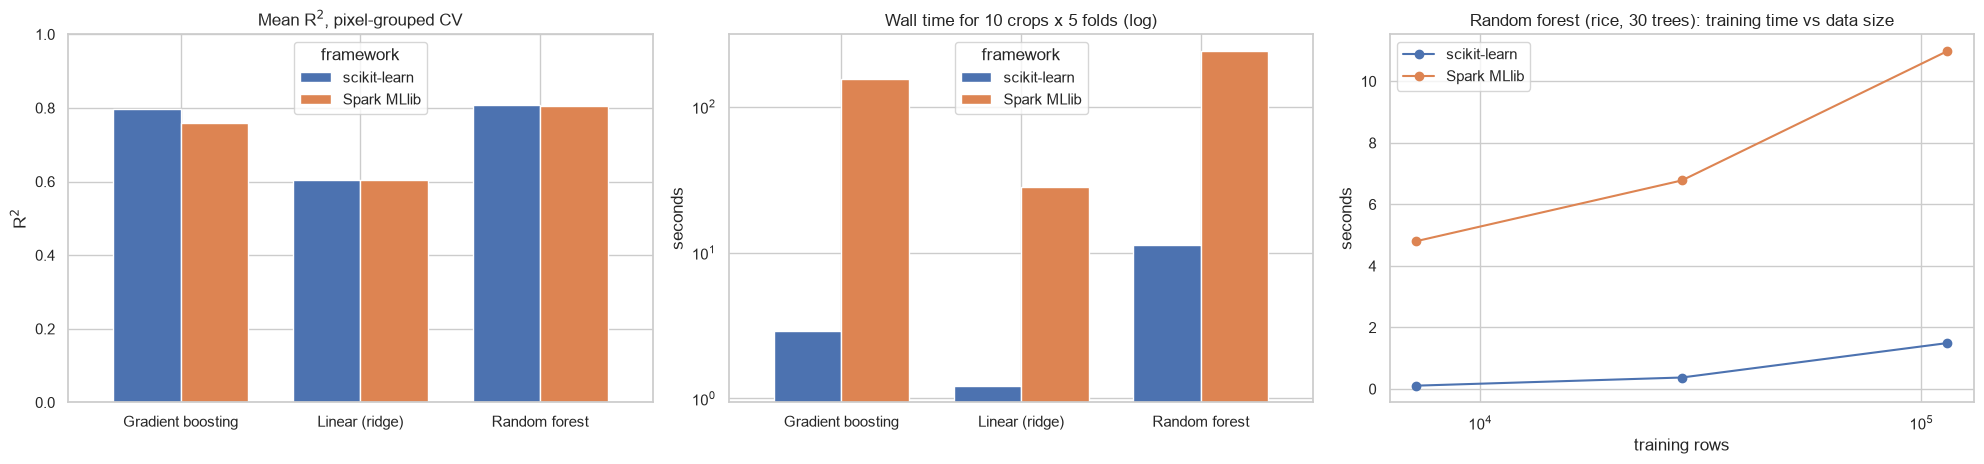

In [8]:
COLORS = {"scikit-learn": "#4C72B0", "Spark MLlib": "#DD8452"}   # the same colour for a framework in every panel
fig, axes = plt.subplots(1, 3, figsize=(20, 4.8))
s = summary[summary["model"] != "ExtraTrees (reference)"]
s.pivot(index="model", columns="framework", values="r2")[list(COLORS)].plot.bar(
    ax=axes[0], rot=0, width=0.75, color=list(COLORS.values()))
axes[0].set(title="Mean R$^2$, pixel-grouped CV", ylabel="R$^2$", xlabel="", ylim=(0, 1))
s.pivot(index="model", columns="framework", values="wall seconds (10 crops x 5 folds)")[list(COLORS)].plot.bar(
    ax=axes[1], rot=0, width=0.75, logy=True, color=list(COLORS.values()))
axes[1].set(title="Wall time for 10 crops x 5 folds (log)", ylabel="seconds", xlabel="")
scaling.rename(columns={"scikit-learn (s)": "scikit-learn", "Spark MLlib (s)": "Spark MLlib"}).plot(
    x="training rows", y=list(COLORS), marker="o", ax=axes[2], logx=True, color=list(COLORS.values()))
axes[2].set(title="Random forest (rice, 30 trees): training time vs data size", ylabel="seconds")
plt.tight_layout()
E.save_fig(fig, "m16_summary")
plt.show()

## Findings

- **Same algorithm, same accuracy.** Where both libraries implement the same model the honest scores agree: ridge
  regression reaches R² 0.604 on both sides (identical to three decimals for every crop), the random forest 0.808 with
  scikit-learn and 0.806 with MLlib (per crop within ±0.008). MLlib is a drop-in replacement for the classic models of
  m01 once the data outgrow one machine.
- **Gradient boosting is where the libraries part.** MLlib's `GBTRegressor` reaches R² 0.760 against 0.797 for
  scikit-learn's `HistGradientBoostingRegressor` with the same rounds, depth and step (-0.037 on average, -0.020 to -0.049
  per crop). The two are different implementations: MLlib bins every input into 32 values and lets a leaf hold a single
  cell, scikit-learn's histogram boosting uses up to 255 bins and at least 20 cells per leaf (the defaults of both
  libraries). Equal settings therefore do not give the same model; MLlib's boosting would need its own tuning.
- **On one machine Spark is the slower tool.** The 50 fits per model (10 crops x 5 folds) took 28 s for ridge in MLlib
  against 1.2 s in scikit-learn, 241 s against 11 s for the random forest and 155 s against 2.9 s for boosting: 21 to 54
  times longer with the same 6 cores. At 9,129 rows a Spark job is mostly fixed cost: planning, scheduling tasks and moving
  data between Python and the JVM.
- **Spark's fixed cost is amortised, not overtaken.** With 16 times more training rows the random forest took 2.3 times
  longer in MLlib (4.8 to 11.0 s) and 13.8 times longer in scikit-learn (0.11 to 1.49 s), so the gap narrows from about
  45x to 7x. It does not close on one machine: every extra 10,000 rows still cost MLlib 0.58 s against 0.13 s.
- **What it means for this project.** The province table is a scikit-learn job: the same scores in a fraction of the
  time, which is why m01-m15 use scikit-learn and PyTorch. MLlib is the scalable path, and this notebook shows it gives
  the same answers: it becomes the right tool when the table no longer fits one machine (all of Indonesia on a 100 m
  grid would be about 190 million cells, tens of gigabytes of inputs), because the same `pyspark.ml` pipeline then runs
  unchanged on a cluster, in the same engine as the Sedona ETL of notebook 06.